# Tugas Data Visualization — Pelanggan Online Food Delivery

**Mata Kuliah:** Data Mining — Pertemuan 6
**Dataset:** Online Food Delivery (388 responden, Bangalore)
**Tools:** Python, Pandas, Matplotlib, Seaborn


# 1. Upload Dataset
Mengunggah file `online_food_delivery_dataset.csv` dari komputer ke Google Colab. File bersifat sementara, jadi upload ulang bila sesi Colab berakhir.

In [5]:
# ============================================
# TUGAS DATA VISUALIZATION - DATASET ONLINE FOOD DELIVERY
# Nama : [ Yonri Yonic Rahayaan ]
# NIM  : [ 2218026 ]
# ============================================

from google.colab import files

uploaded = files.upload()

# Ambil nama file yang diunggah
FILE = list(uploaded.keys())[0]
print("\nFile yang diunggah:", FILE)

Saving online food delivery dataset.csv to online food delivery dataset.csv

File yang diunggah: online food delivery dataset.csv


# 2. Import Libraries
Mengimpor library untuk pengolahan data (pandas, numpy) dan visualisasi (matplotlib, seaborn), serta mengatur tampilan grafik.


In [6]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan grafik
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

print("Library berhasil diimpor.")

Library berhasil diimpor.


# 3. Load Dataset
Membaca file CSV yang sudah diunggah ke dalam DataFrame, lalu menampilkan ukuran dan lima baris pertama data.

In [7]:
df = pd.read_csv(FILE)

print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (388, 14)


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


# 4. Data Understanding
Mengenali struktur data: tipe kolom, statistik deskriptif, nilai kosong, dan duplikasi.

**Temuan:** tidak ada missing value; kolom `Unnamed: 13` identik dengan `Output` (redundan); `Feedback` memiliki nilai `Negative ` dengan spasi di belakang; ada ejaan tidak baku (`Self Employeed`, `House wife`); 103 baris identik tidak dihapus karena dataset tidak punya ID responden.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         388 non-null    int64  
 1   Gender                      388 non-null    object 
 2   Marital Status              388 non-null    object 
 3   Occupation                  388 non-null    object 
 4   Monthly Income              388 non-null    object 
 5   Educational Qualifications  388 non-null    object 
 6   Family size                 388 non-null    int64  
 7   Customer Type               388 non-null    object 
 8   latitude                    388 non-null    float64
 9   longitude                   388 non-null    float64
 10  Pin code                    388 non-null    int64  
 11  Output                      388 non-null    object 
 12  Feedback                    388 non-null    object 
 13  Unnamed: 13                 388 non

In [9]:
display(df.describe().round(2))
display(df.describe(include="object"))

,Age,Family size,latitude,longitude,Pin code
count,388.00,388.00,388.00,388.00,388.00
mean,24.63,3.28,12.97,77.60,560040.11
std,2.98,1.35,0.04,0.05,31.40
min,18.00,1.00,12.87,77.48,560001.00
25%,23.00,2.00,12.94,77.57,560010.75
50%,24.00,3.00,12.98,77.59,560033.50
75%,26.00,4.00,13.00,77.63,560068.00
max,33.00,6.00,13.10,77.76,560109.00


,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Customer Type,Output,Feedback,Unnamed: 13
count,388,388,388,388,388,388,388,388,388
unique,2,3,4,5,5,3,2,2,2
top,Male,Single,Student,No Income,Graduate,Regular,Yes,Positive,Yes
freq,222,268,207,187,177,218,301,317,301


In [10]:
print("Missing value per kolom:")
print(df.isna().sum())
print("\nBaris duplikat penuh :", df.duplicated().sum())
print("'Unnamed: 13' identik dengan 'Output'? ->", (df["Output"] == df["Unnamed: 13"]).all())
print("Nilai unik Feedback  :", df["Feedback"].unique())

Missing value per kolom:
Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
Unnamed: 13                   0
dtype: int64

Baris duplikat penuh : 103
'Unnamed: 13' identik dengan 'Output'? -> True
Nilai unik Feedback  : ['Positive' 'Negative ']


# 5. Data Cleaning
Menghapus kolom duplikat, merapikan teks dan nama kolom, serta membuat kolom numerik (1 = Yes/Positive) untuk menghitung persentase dan korelasi.

In [11]:
df = df.drop(columns=["Unnamed: 13"])
df["Feedback"] = df["Feedback"].str.strip()
df["Occupation"] = df["Occupation"].replace({"Self Employeed": "Self Employed",
                                             "House wife": "Housewife"})
df = df.rename(columns={"Family size": "Family_Size", "Marital Status": "Marital_Status",
                        "Monthly Income": "Monthly_Income", "Customer Type": "Customer_Type",
                        "Educational Qualifications": "Education", "Pin code": "Pin_Code"})

df["Output_Num"]   = (df["Output"] == "Yes").astype(int)
df["Feedback_Num"] = (df["Feedback"] == "Positive").astype(int)

income_order = ["No Income", "Below Rs.10000", "10001 to 25000", "25001 to 50000", "More than 50000"]
edu_order    = ["Uneducated", "School", "Graduate", "Post Graduate", "Ph.D"]

print("Ukuran data setelah cleaning:", df.shape)
df.head()

Ukuran data setelah cleaning: (388, 15)


,Age,Gender,Marital_Status,Occupation,Monthly_Income,Education,Family_Size,Customer_Type,latitude,longitude,Pin_Code,Output,Feedback,Output_Num,Feedback_Num
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,1,1
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,1,1
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,1,0
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,1,1
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,1,1


# 6. Visualisasi
Membuat 7 visualisasi untuk mengeksplorasi data. Setiap visualisasi dilengkapi judul, label sumbu, legenda, dan kesimpulan di bawah grafik:

1. Histogram — distribusi usia
2. Bar chart — gender, status pernikahan, dan pekerjaan
3. Donut chart — proporsi Output dan Feedback
4. Bar chart persentase — "Yes" menurut pekerjaan dan status pernikahan
5. Boxplot — sebaran usia menurut Output
6. Line chart — tren persentase "Yes" menurut usia
7. Heatmap — korelasi antar variabel

## Visualisasi 1: Histogram Usia

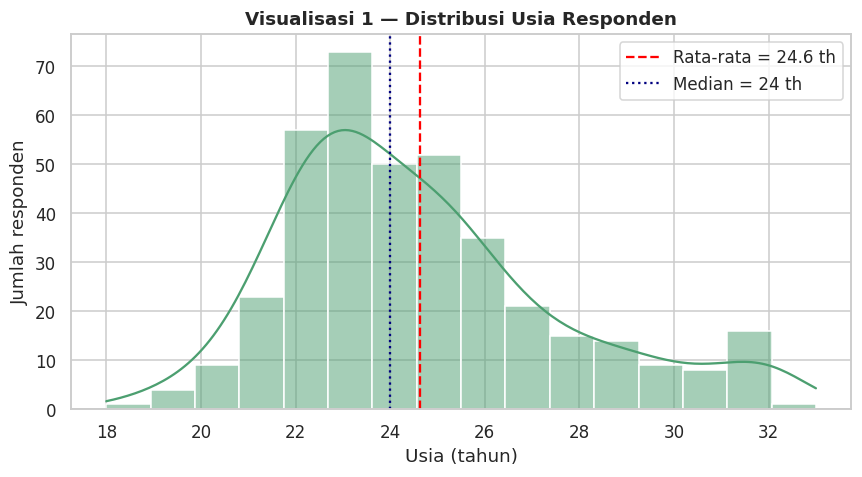

Kesimpulan Visualisasi 1:
Usia responden 18-33 tahun dengan rata-rata ±24,6 tahun. Sekitar 69% berusia 22-26 tahun,
sehingga pelanggan dalam data ini didominasi anak muda / dewasa awal.


In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["Age"], bins=16, kde=True, color="#4C9F70", ax=ax)
ax.axvline(df["Age"].mean(), color="red", ls="--", label=f"Rata-rata = {df['Age'].mean():.1f} th")
ax.axvline(df["Age"].median(), color="navy", ls=":", label=f"Median = {df['Age'].median():.0f} th")
ax.set_title("Visualisasi 1 — Distribusi Usia Responden")
ax.set_xlabel("Usia (tahun)"); ax.set_ylabel("Jumlah responden")
ax.legend()
plt.tight_layout(); plt.show()

print("Kesimpulan Visualisasi 1:")
print("Usia responden 18-33 tahun dengan rata-rata ±24,6 tahun. Sekitar 69% berusia 22-26 tahun,")
print("sehingga pelanggan dalam data ini didominasi anak muda / dewasa awal.")

# Visualisasi 2 : Bar chart — gender, status pernikahan, dan pekerjaan

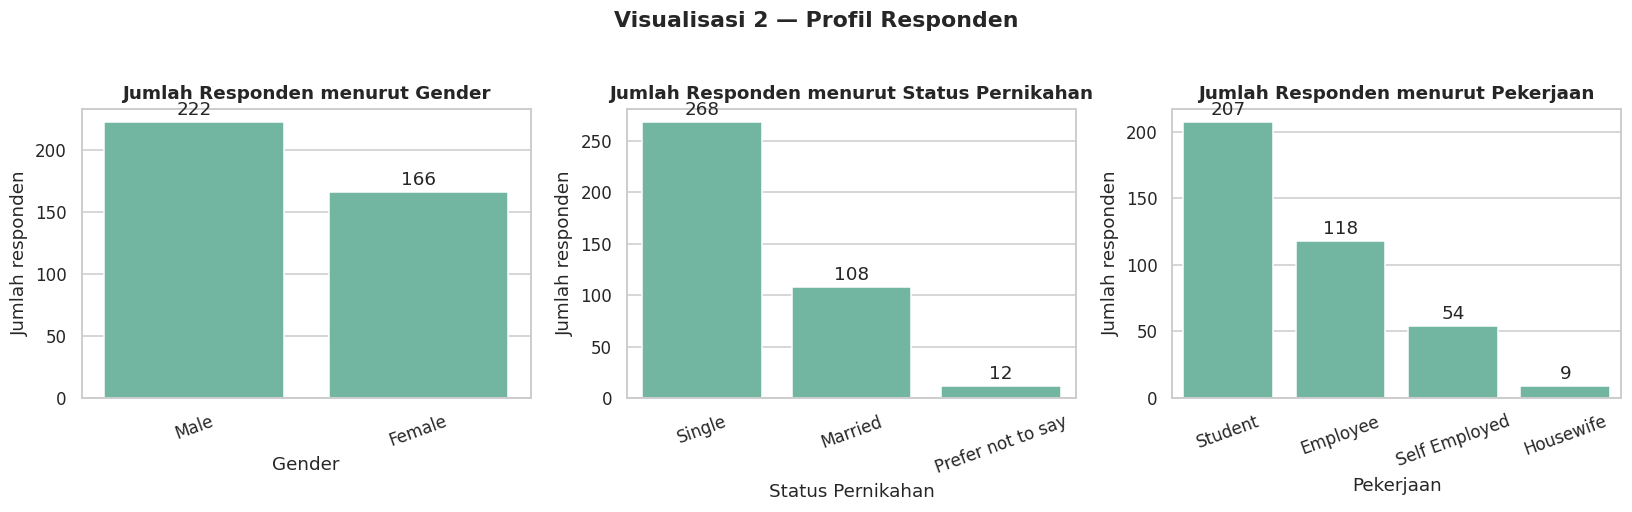

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, title in zip(axes, ["Gender", "Marital_Status", "Occupation"],
                          ["Gender", "Status Pernikahan", "Pekerjaan"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, padding=2)
    ax.set_title(f"Jumlah Responden menurut {title}")
    ax.set_xlabel(title); ax.set_ylabel("Jumlah responden")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Visualisasi 2 — Profil Responden", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**Kesimpulan Visualisasi 2:** Responden laki-laki lebih banyak (222 vs 166). Mayoritas berstatus lajang (268 dari 388) dan pelajar adalah kelompok terbesar (207 orang, ±53%). Hasil analisis lebih mencerminkan perilaku pelanggan muda dan lajang.

# Visualisasi 3 : Donut chart — proporsi Output dan Feedback

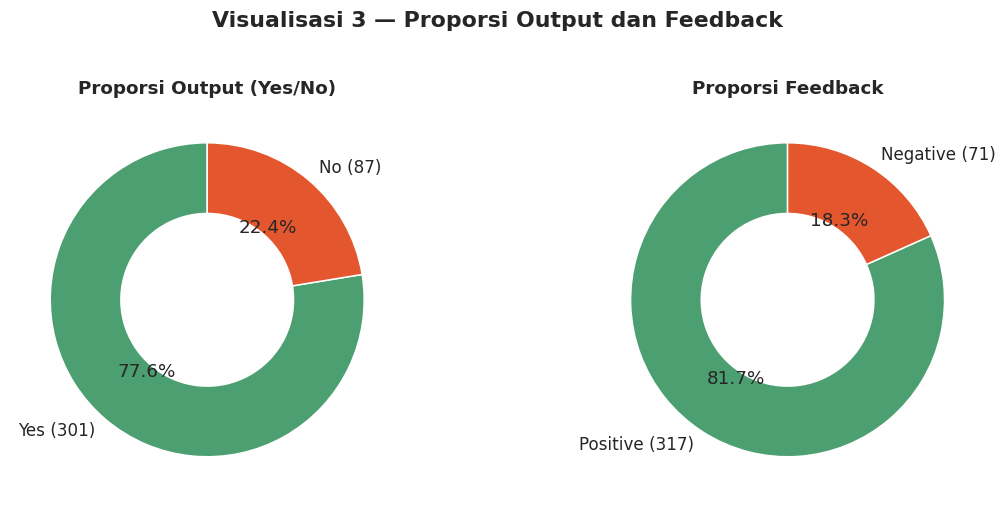

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, title in zip(axes, ["Output", "Feedback"],
                          ["Proporsi Output (Yes/No)", "Proporsi Feedback"]):
    vc = df[col].value_counts()
    ax.pie(vc, labels=[f"{i} ({v})" for i, v in vc.items()], autopct="%1.1f%%",
           startangle=90, wedgeprops=dict(width=0.45), colors=["#4C9F70", "#E4572E"])
    ax.set_title(title)
fig.suptitle("Visualisasi 3 — Proporsi Output dan Feedback", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**Kesimpulan Visualisasi 3:** Sebanyak 77,6% responden menjawab "Yes" pada Output dan 81,7% memberi feedback positif. Data tidak seimbang (imbalanced), sehingga perlu diperhatikan bila nanti dipakai untuk model klasifikasi.

# Visualisasi 4 : Bar chart persentase — "Yes" menurut pekerjaan dan status pernikahan

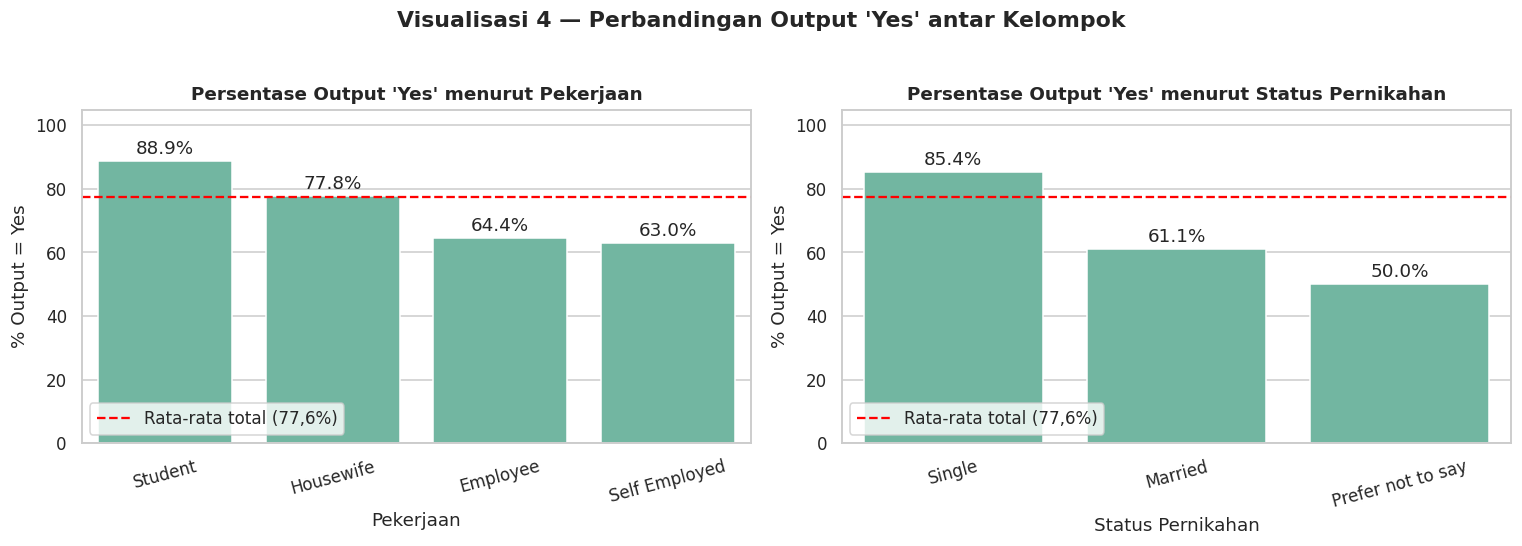

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, title in zip(axes, ["Occupation", "Marital_Status"], ["Pekerjaan", "Status Pernikahan"]):
    rate = df.groupby(col)["Output_Num"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(df["Output_Num"].mean()*100, color="red", ls="--", label="Rata-rata total (77,6%)")
    for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", padding=2)
    ax.set_ylim(0, 105)
    ax.set_title(f"Persentase Output 'Yes' menurut {title}")
    ax.set_xlabel(title); ax.set_ylabel("% Output = Yes")
    ax.tick_params(axis="x", rotation=15); ax.legend(loc="lower left")
fig.suptitle("Visualisasi 4 — Perbandingan Output 'Yes' antar Kelompok", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**Kesimpulan Visualisasi 4:** Pelajar memiliki persentase "Yes" tertinggi (88,9%), jauh di atas karyawan (64,4%) dan wirausaha (63,0%). Responden lajang 85,4% vs menikah 61,1%. Kedua pola ini saling terkait karena hampir semua pelajar berstatus lajang. Kategori Housewife hanya 9 responden sehingga tidak cukup untuk disimpulkan.

# Visualisasi 5 : Boxplot — sebaran usia menurut Output

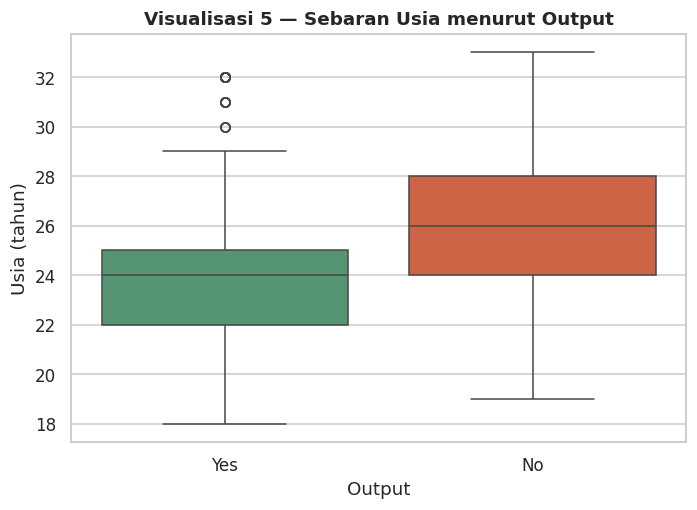

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 4.8))
sns.boxplot(data=df, x="Output", y="Age", order=["Yes", "No"],
            palette=["#4C9F70", "#E4572E"], ax=ax)
ax.set_title("Visualisasi 5 — Sebaran Usia menurut Output")
ax.set_xlabel("Output"); ax.set_ylabel("Usia (tahun)")
plt.tight_layout(); plt.show()

**Kesimpulan Visualisasi 5:** Responden dengan Output "Yes" cenderung lebih muda (median 24 tahun) dibanding "No" (median 26 tahun). Terdapat beberapa outlier usia di atas ±30 tahun.

# Visualisasi 6 : Line chart — tren persentase "Yes" menurut usia

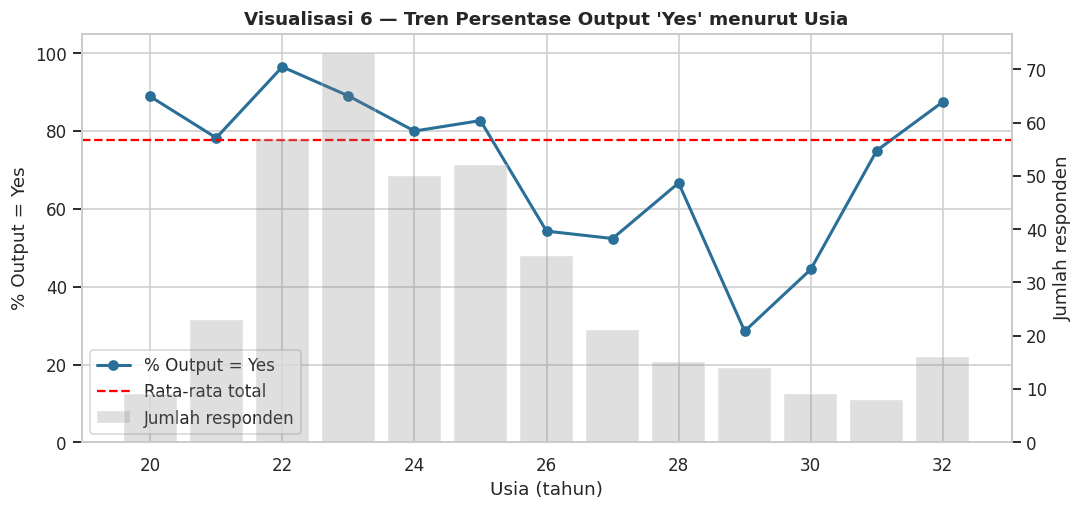

In [17]:
age_rate = df.groupby("Age")["Output_Num"].agg(["mean", "count"])
age_rate = age_rate[age_rate["count"] >= 5]     # hanya usia dengan >= 5 responden

fig, ax1 = plt.subplots(figsize=(10, 4.8))
ax1.plot(age_rate.index, age_rate["mean"]*100, marker="o", color="#2A6F97", lw=2, label="% Output = Yes")
ax1.axhline(df["Output_Num"].mean()*100, color="red", ls="--", label="Rata-rata total")
ax1.set_xlabel("Usia (tahun)"); ax1.set_ylabel("% Output = Yes"); ax1.set_ylim(0, 105)
ax2 = ax1.twinx()
ax2.bar(age_rate.index, age_rate["count"], alpha=0.25, color="gray", label="Jumlah responden")
ax2.set_ylabel("Jumlah responden"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left")
ax1.set_title("Visualisasi 6 — Tren Persentase Output 'Yes' menurut Usia")
plt.tight_layout(); plt.show()

**Kesimpulan Visualisasi 6:** Persentase "Yes" tinggi (78–96%) pada usia 20–25 tahun, lalu turun pada usia 26–30 tahun (terendah 29% di usia 29). Jumlah responden usia di atas 28 sedikit, sehingga kenaikan di usia 31–32 perlu dibaca dengan hati-hati.

# Visualisasi 7 : Heatmap — korelasi antar variabel

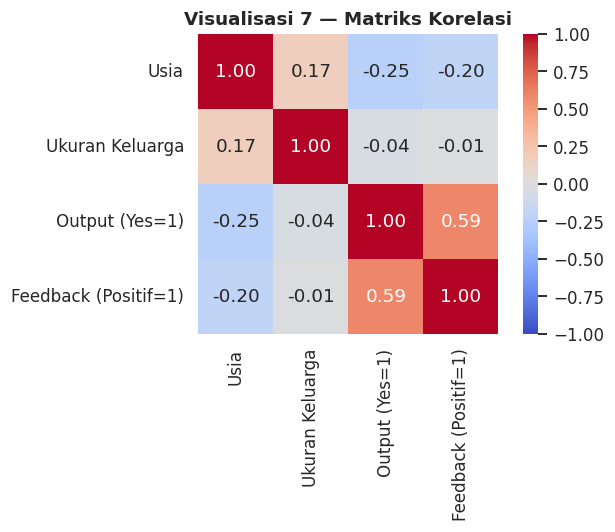

In [18]:
corr = df[["Age", "Family_Size", "Output_Num", "Feedback_Num"]].corr()
corr.columns = corr.index = ["Usia", "Ukuran Keluarga", "Output (Yes=1)", "Feedback (Positif=1)"]

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Visualisasi 7 — Matriks Korelasi")
plt.tight_layout(); plt.show()

# Visualisasi 7. Kesimpulan

1. Responden didominasi anak muda (rata-rata ±24,6 tahun), lajang, dan pelajar (Visualisasi 1 dan 2).
2. Target tidak seimbang: 77,6% `Output = Yes` dan 81,7% feedback positif (Visualisasi 3).
3. Tingkat "Yes" lebih tinggi pada pelajar (88,9%) dan lajang (85,4%) dibanding karyawan, wirausaha, dan yang sudah menikah (Visualisasi 4).
4. Responden "Yes" cenderung lebih muda; persentase "Yes" tinggi pada usia 20–25 tahun dan turun pada usia 26–30 tahun (Visualisasi 5 dan 6).
5. Feedback adalah variabel yang paling berkaitan dengan Output (r = 0,59), sedangkan ukuran keluarga hampir tidak berpengaruh (Visualisasi 7).

**Keterbatasan:** sampel kecil (388), beberapa kategori sangat sedikit, dataset tanpa ID responden, dan hubungan yang ditemukan bersifat asosiasi (bukan sebab-akibat).

**Saran:** lanjutkan ke pemodelan (Decision Tree / Logistic Regression) dengan penanganan data imbalanced dan uji Chi-square.